In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

Matplotlib is building the font cache; this may take a moment.


In [2]:
# Locate the dataset
possible_paths = [
    Path("data/ai4i2020.csv"),
    Path("../data/ai4i2020.csv")
]

csv_path = next(
    (path for path in possible_paths if path.exists()),
    None
)

if csv_path is None:
    raise FileNotFoundError("Cannot find ai4i2020.csv")

In [3]:
# Load dataset
df = pd.read_csv(csv_path)

In [4]:
# Display dataset information
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 records:")
display(df.head())

print("\nMissing values:")
display(df.isnull().sum())

print("\nStatistical summary:")
display(df.describe())

Dataset loaded successfully!
Dataset shape: (10000, 14)

Column names:
['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']

First 5 records:


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0



Missing values:


UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64


Statistical summary:


,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [5]:
# 2. Column data types
print("\nColumn data types:")
print(df.dtypes)


Column data types:
UDI                          int64
Product ID                     str
Type                           str
Air temperature [K]        float64
Process temperature [K]    float64
Rotational speed [rpm]       int64
Torque [Nm]                float64
Tool wear [min]              int64
Machine failure              int64
TWF                          int64
HDF                          int64
PWF                          int64
OSF                          int64
RNF                          int64
dtype: object


In [6]:
# 3. Check duplicate records
print("\nDuplicate records:", df.duplicated().sum())


Duplicate records: 0


In [7]:
# 4. Machine failure distribution
print("\nMachine failure distribution:")
print(df["Machine failure"].value_counts())


Machine failure distribution:
Machine failure
0    9661
1     339
Name: count, dtype: int64


In [8]:
# 5. Failure percentages
print("\nMachine failure percentages:")
print(
    df["Machine failure"]
    .value_counts(normalize=True) * 100
)


Machine failure percentages:
Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64


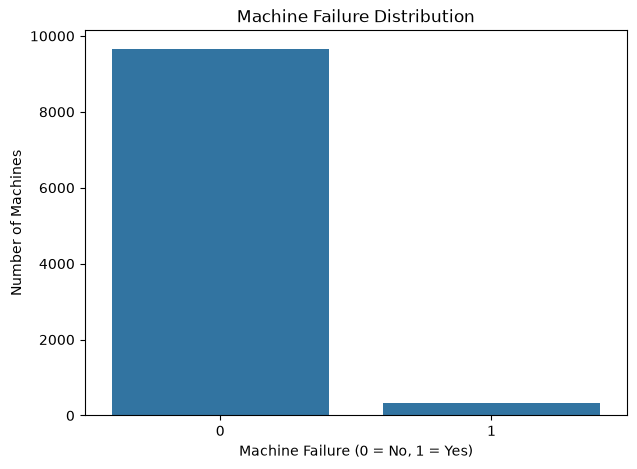

In [9]:
#Visualize machine failures
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Machine failure"
)

plt.title("Machine Failure Distribution")
plt.xlabel("Machine Failure (0 = No, 1 = Yes)")
plt.ylabel("Number of Machines")

plt.show()

In [10]:
# Create a copy of the original dataset
data = df.copy()

In [11]:
# Remove identifiers and failure-mode columns
columns_to_drop = [
    "UDI",
    "Product ID",
    "TWF",
    "HDF",
    "PWF",
    "OSF",
    "RNF"
]

data = data.drop(columns=columns_to_drop)

In [13]:
# Separate input features and target
X = data.drop(columns=["Machine failure"])
y = data["Machine failure"]

print("Preprocessing completed!")

Preprocessing completed!


In [14]:
print("\nInput features:")
print(X.columns.tolist())

print("\nTarget variable:")
print(y.name)

print("\nFeature dataset shape:", X.shape)
print("Target dataset shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())


Input features:
['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']

Target variable:
Machine failure

Feature dataset shape: (10000, 6)
Target dataset shape: (10000,)

Target distribution:
Machine failure
0    9661
1     339
Name: count, dtype: int64


In [15]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training and testing split completed!")

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

print("Training failure distribution:")
print(y_train.value_counts())

print("\nTesting failure distribution:")
print(y_test.value_counts())

Training and testing split completed!
Training records: 8000
Testing records: 2000
Training failure distribution:
Machine failure
0    7729
1     271
Name: count, dtype: int64

Testing failure distribution:
Machine failure
0    1932
1      68
Name: count, dtype: int64


In [16]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training and testing split completed!")

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

print("Training failure distribution:")
print(y_train.value_counts())

print("\nTesting failure distribution:")
print(y_test.value_counts())

Training and testing split completed!
Training records: 8000
Testing records: 2000
Training failure distribution:
Machine failure
0    7729
1     271
Name: count, dtype: int64

Testing failure distribution:
Machine failure
0    1932
1      68
Name: count, dtype: int64


In [17]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Identify categorical columns
categorical_features = ["Type"]

# Create preprocessing transformer
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ],
    remainder="passthrough"
)

# Fit using training data only
X_train_processed = preprocessor.fit_transform(X_train)

# Transform testing data
X_test_processed = preprocessor.transform(X_test)

print("Feature encoding completed!")

print("Original training shape:", X_train.shape)
print("Processed training shape:", X_train_processed.shape)

print("Original testing shape:", X_test.shape)
print("Processed testing shape:", X_test_processed.shape)

print("\nEncoded feature names:")
print(preprocessor.get_feature_names_out())

Feature encoding completed!
Original training shape: (8000, 6)
Processed training shape: (8000, 8)
Original testing shape: (2000, 6)
Processed testing shape: (2000, 8)

Encoded feature names:
['categorical__Type_H' 'categorical__Type_L' 'categorical__Type_M'
 'remainder__Air temperature [K]' 'remainder__Process temperature [K]'
 'remainder__Rotational speed [rpm]' 'remainder__Torque [Nm]'
 'remainder__Tool wear [min]']


In [18]:
from sklearn.ensemble import RandomForestClassifier

# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=15,
    min_samples_split=5,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

print("Random Forest model created successfully!")

Random Forest model created successfully!


In [19]:
# Train Random Forest
rf_model.fit(X_train_processed, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [20]:
# Predict machine failures
rf_predictions = rf_model.predict(X_test_processed)

# Predict failure probabilities
rf_probabilities = rf_model.predict_proba(X_test_processed)[:, 1]

print("Predictions completed!")

print("\nFirst 10 actual values:")
print(y_test.iloc[:10].values)

print("\nFirst 10 predicted values:")
print(rf_predictions[:10])

Predictions completed!

First 10 actual values:
[0 0 0 0 0 0 0 0 0 0]

First 10 predicted values:
[1 0 0 0 0 0 0 0 0 0]


In [21]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

print("RANDOM FOREST MODEL PERFORMANCE")

print("\nAccuracy:",
      accuracy_score(y_test, rf_predictions))

print("Precision:",
      precision_score(y_test, rf_predictions, zero_division=0))

print("Recall:",
      recall_score(y_test, rf_predictions, zero_division=0))

print("F1 Score:",
      f1_score(y_test, rf_predictions, zero_division=0))

print("ROC-AUC:",
      roc_auc_score(y_test, rf_probabilities))

print("\nClassification Report:")
print(classification_report(y_test, rf_predictions, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_predictions))

RANDOM FOREST MODEL PERFORMANCE

Accuracy: 0.972
Precision: 0.5652173913043478
Recall: 0.7647058823529411
F1 Score: 0.65
ROC-AUC: 0.9667290829375228

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.98      0.99      1932
           1       0.57      0.76      0.65        68

    accuracy                           0.97      2000
   macro avg       0.78      0.87      0.82      2000
weighted avg       0.98      0.97      0.97      2000


Confusion Matrix:
[[1892   40]
 [  16   52]]


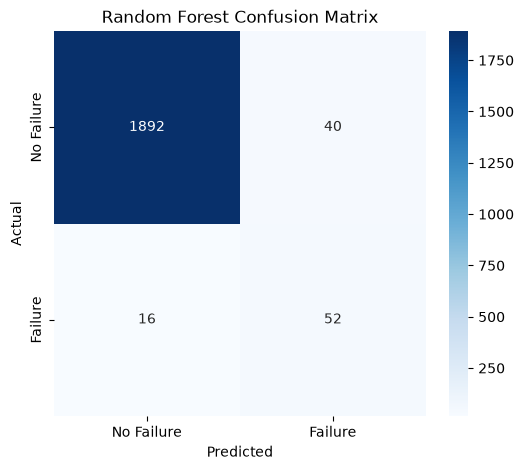

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, rf_predictions)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Failure", "Failure"],
    yticklabels=["No Failure", "Failure"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest Confusion Matrix")

plt.show()

In [27]:
from xgboost import XGBClassifier

# Calculate class imbalance ratio
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_weight = negative_count / positive_count

# Create XGBoost model
xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_weight,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

print("XGBoost model created successfully!")



XGBoost model created successfully!


In [24]:
# Predict machine failures
xgb_predictions = xgb_model.predict(X_test_processed)

# Predict failure probabilities
xgb_probabilities = xgb_model.predict_proba(
    X_test_processed
)[:, 1]

print("XGBoost predictions completed!")

print("\nFirst 10 actual values:")
print(y_test.iloc[:10].values)

print("\nFirst 10 predicted values:")
print(xgb_predictions[:10])

NotFittedError: need to call fit or load_model beforehand

In [25]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

print("XGBOOST MODEL PERFORMANCE")

print("Accuracy:",
      accuracy_score(y_test, xgb_predictions))

print("Precision:",
      precision_score(y_test, xgb_predictions, zero_division=0))

print("Recall:",
      recall_score(y_test, xgb_predictions, zero_division=0))

print("F1 Score:",
      f1_score(y_test, xgb_predictions, zero_division=0))

print("ROC-AUC:",
      roc_auc_score(y_test, xgb_probabilities))

print("\nClassification Report:")
print(classification_report(
    y_test,
    xgb_predictions,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, xgb_predictions))

XGBOOST MODEL PERFORMANCE


NameError: name 'xgb_predictions' is not defined